In [1]:
import numpy as np
import pandas as pd
# %matplotlib widget
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns
import plotly.graph_objects as go
import pathlib
from tqdm import tqdm

module_dir = pathlib.Path("").parent.resolve()
root_dir = module_dir.parent
dir_results = root_dir.joinpath("results")
dir_report = dir_results.joinpath("report")
dir_report.mkdir(parents=True, exist_ok=True)
dir_comms = dir_results.joinpath("comms")
dir_comms.mkdir(parents=True, exist_ok=True)
dir_fig = dir_results.joinpath("fig")
dir_fig.mkdir(parents=True, exist_ok=True)

In [2]:
dist_range            = range(100, 1001, 100) # m
ant_ht_range          = range(1, 6, 1) # m
wave_hs_range         = range(1, 14, 1) # m
wave_dp_range         = range(0, 91, 10) # deg   
rand_seed_range       = range(1, 4, 1)
message_length_range  = range(1, 11, 1)
comms_simulation_period = 15 * 60 # sec

## Read and load simulation results to a dataframe

In [3]:
files = []
for dist in dist_range:
    for ant_ht in ant_ht_range:
        for wave_hs in wave_hs_range:
            for wave_dp in wave_dp_range:
                file_name = "comms_{}_{}_{}_{}_.csv".format(int(dist), int(ant_ht), int(wave_hs), round(wave_dp))
                file = dir_comms.joinpath(file_name)
                files.append(str(file))
df = pd.DataFrame() 
for file in tqdm(files):
    df_file = pd.read_csv(str(file), index_col=None)
    df = pd.concat([df, df_file], axis=0, ignore_index=True)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6500/6500 [00:23<00:00, 277.04it/s]


## Variations in results

In [4]:
comms_experiments_params = []
for dist in dist_range:
    for ant_ht in ant_ht_range:
        for wave_hs in wave_hs_range:
            for wave_dp in wave_dp_range:
                for message_length in message_length_range:
                    comms_experiments_params.append({"dist":dist, "ant_ht":ant_ht, "wave_hs":wave_hs, "wave_dp":wave_dp, "message_length":message_length})
ranges = []
for params in tqdm(comms_experiments_params):
    df_exp = df.loc[(df["dist(m)"]             == params["dist"])    & 
                    (df["ant_ht(m)"]           == params["ant_ht"])  &
                    (df["hs(m)"]               == params["wave_hs"]) & 
                    (df["wave_dp_sim(deg)"]    == params["wave_dp"]) &
                    (df["message_length(sec)"] == params["message_length"])]
    variance = df_exp["uninterrupted_time(%)"].max() - df_exp["uninterrupted_time(%)"].min()
    ranges.append(variance)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 65000/65000 [00:42<00:00, 1523.80it/s]


<Axes: >

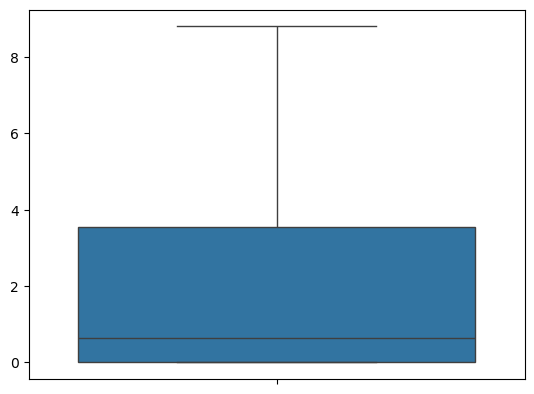

In [5]:
sns.boxplot(ranges, showfliers=False)

## Effects of wave height, relative wave heading, distance between antennas and message length on total uninterrupted transmission time

In [6]:
# Filter data
selected_ant_ht = 3.0 # m
ant_dists = (200, 400, 600, 800) # m
wave_dps = (0, 30, 60, 90) # deg
wave_hss = (1, 3, 5, 7, 9, 11, 13) # m
df_filtered = pd.DataFrame(columns=["dist(m)", "hs(m)", "message_length(sec)", "relative_wave_heading(deg)", "uninterrupted_message_probability", "uninterrupted_time(%)"])
for ant_dist in ant_dists:
    for wave_hs in wave_hss:
        for wave_dp in wave_dps:
            for msg_len in message_length_range:
                df_temp = df.loc[(df["ant_ht(m)"] == selected_ant_ht) & 
                                 (df["dist(m)"]   == ant_dist) &
                                 (df["hs(m)"] == wave_hs) &
                                 (df["wave_dp_sim(deg)"] == wave_dp) &
                                 (df["message_length(sec)"] == msg_len)]
                uninterrupted_time = df_temp["uninterrupted_time(%)"].min()
                uninterrupted_message_probability = df_temp["uninterrupted_message_probability"].min()
                df_filtered.loc[len(df_filtered.index)] = [ant_dist, wave_hs, msg_len, wave_dp, uninterrupted_message_probability, uninterrupted_time]

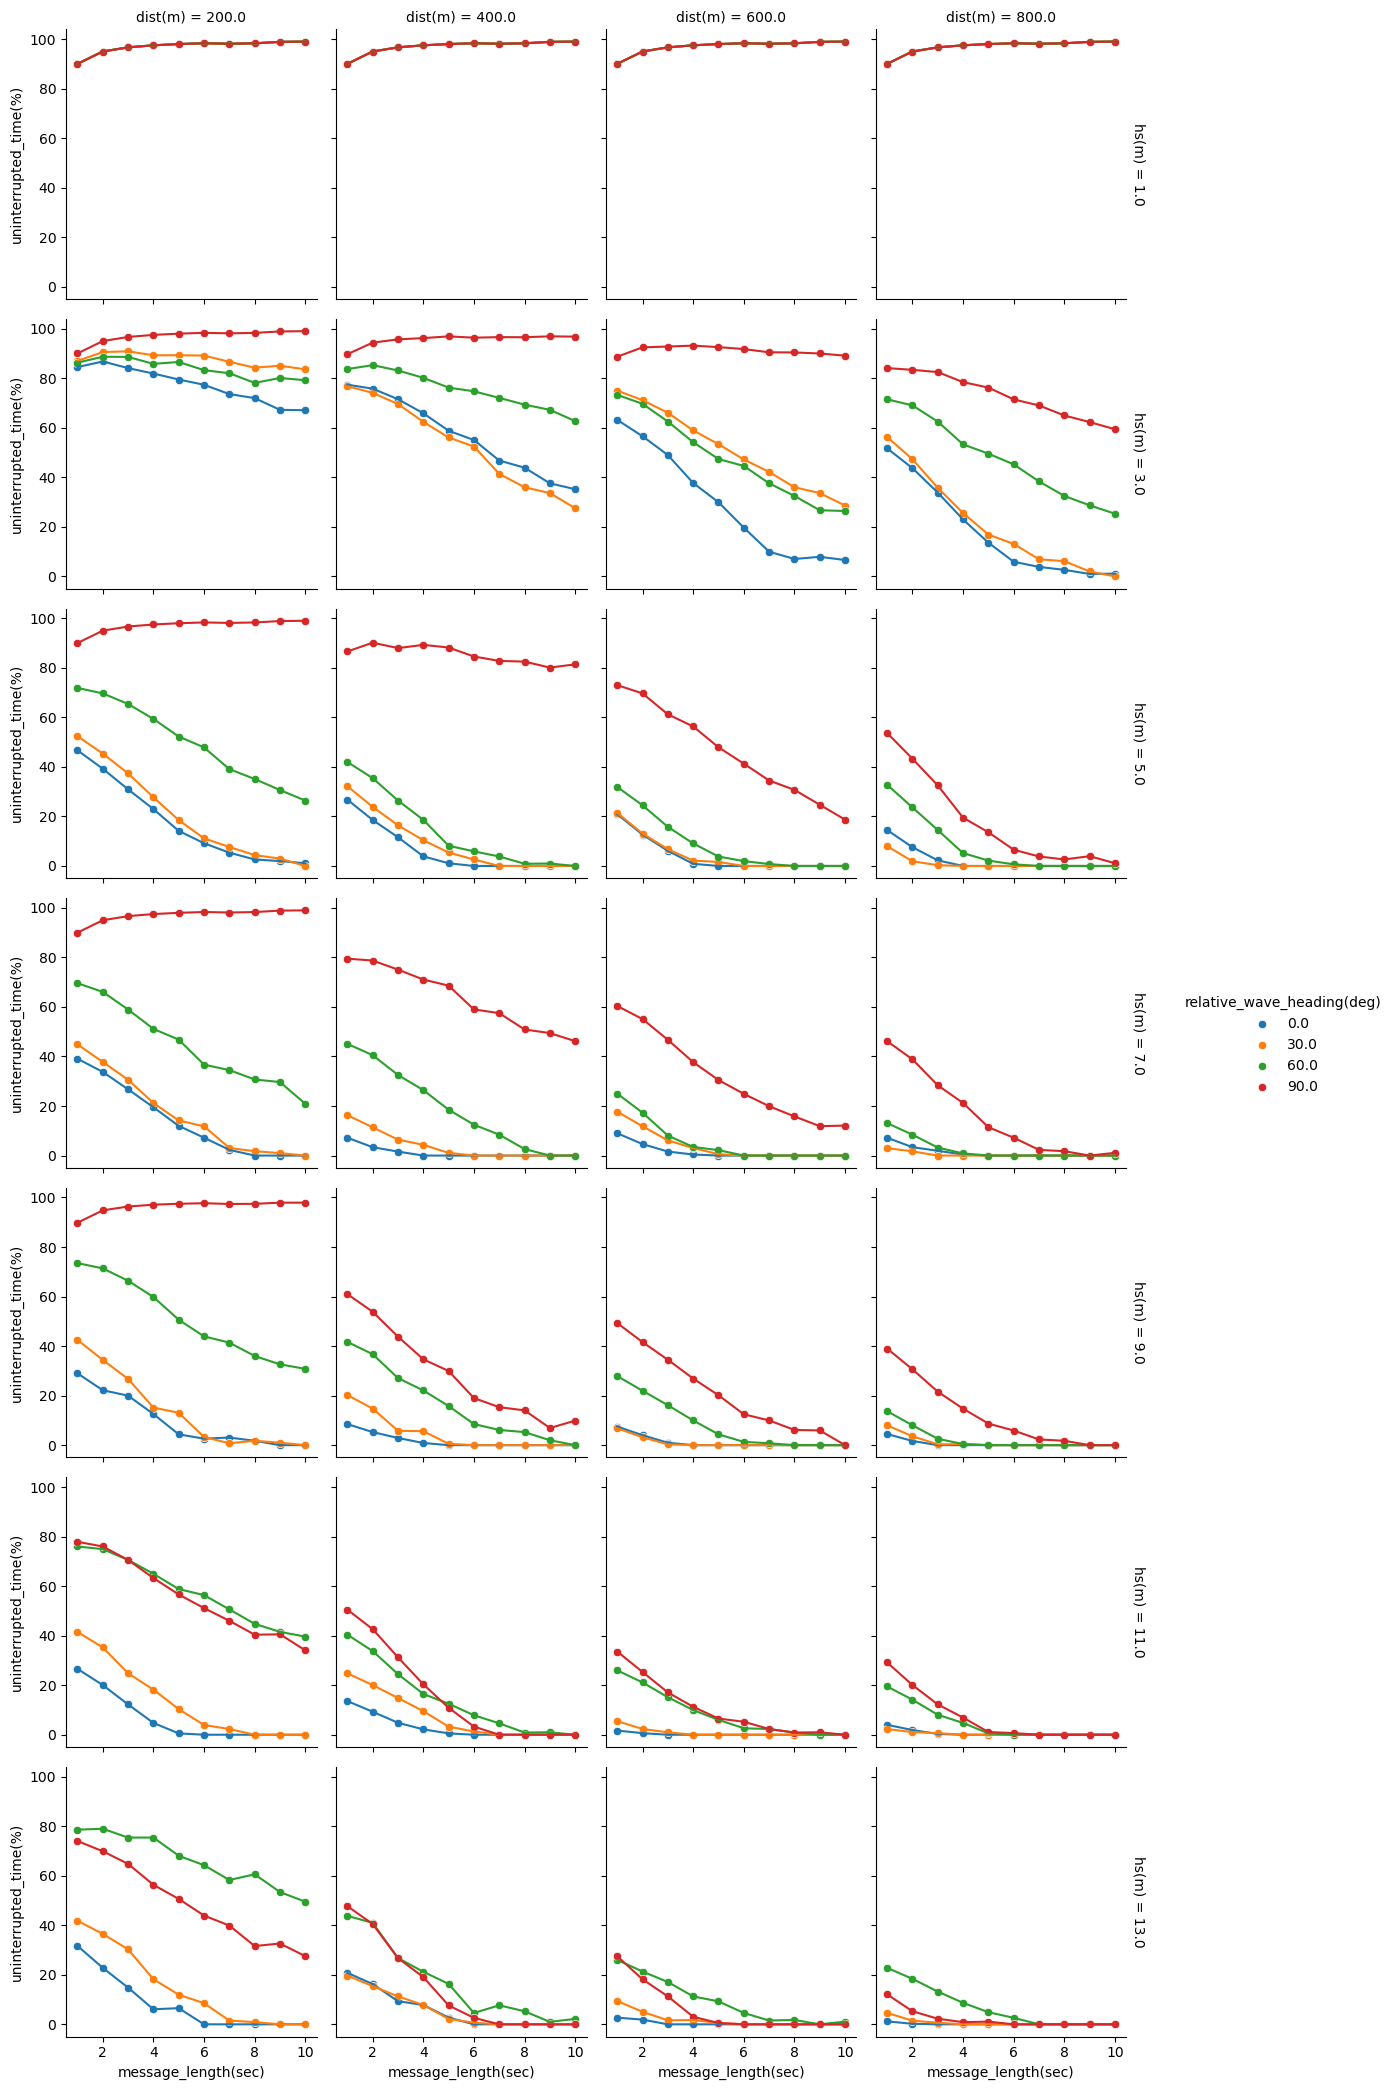

In [7]:
# Set figure size
width = 20
height = 20
plt.rcParams['figure.figsize'] = [width, height]

g = sns.FacetGrid(df_filtered, row="hs(m)", col="dist(m)", hue="relative_wave_heading(deg)", margin_titles=True, legend_out=True)
g.map(sns.lineplot, "message_length(sec)", "uninterrupted_time(%)", estimator="mean", errorbar="ci", err_kws={"alpha":0.1})
g.map(sns.scatterplot, "message_length(sec)", "uninterrupted_time(%)")
g.add_legend()
plt.show()

<Figure size 2000x2000 with 0 Axes>

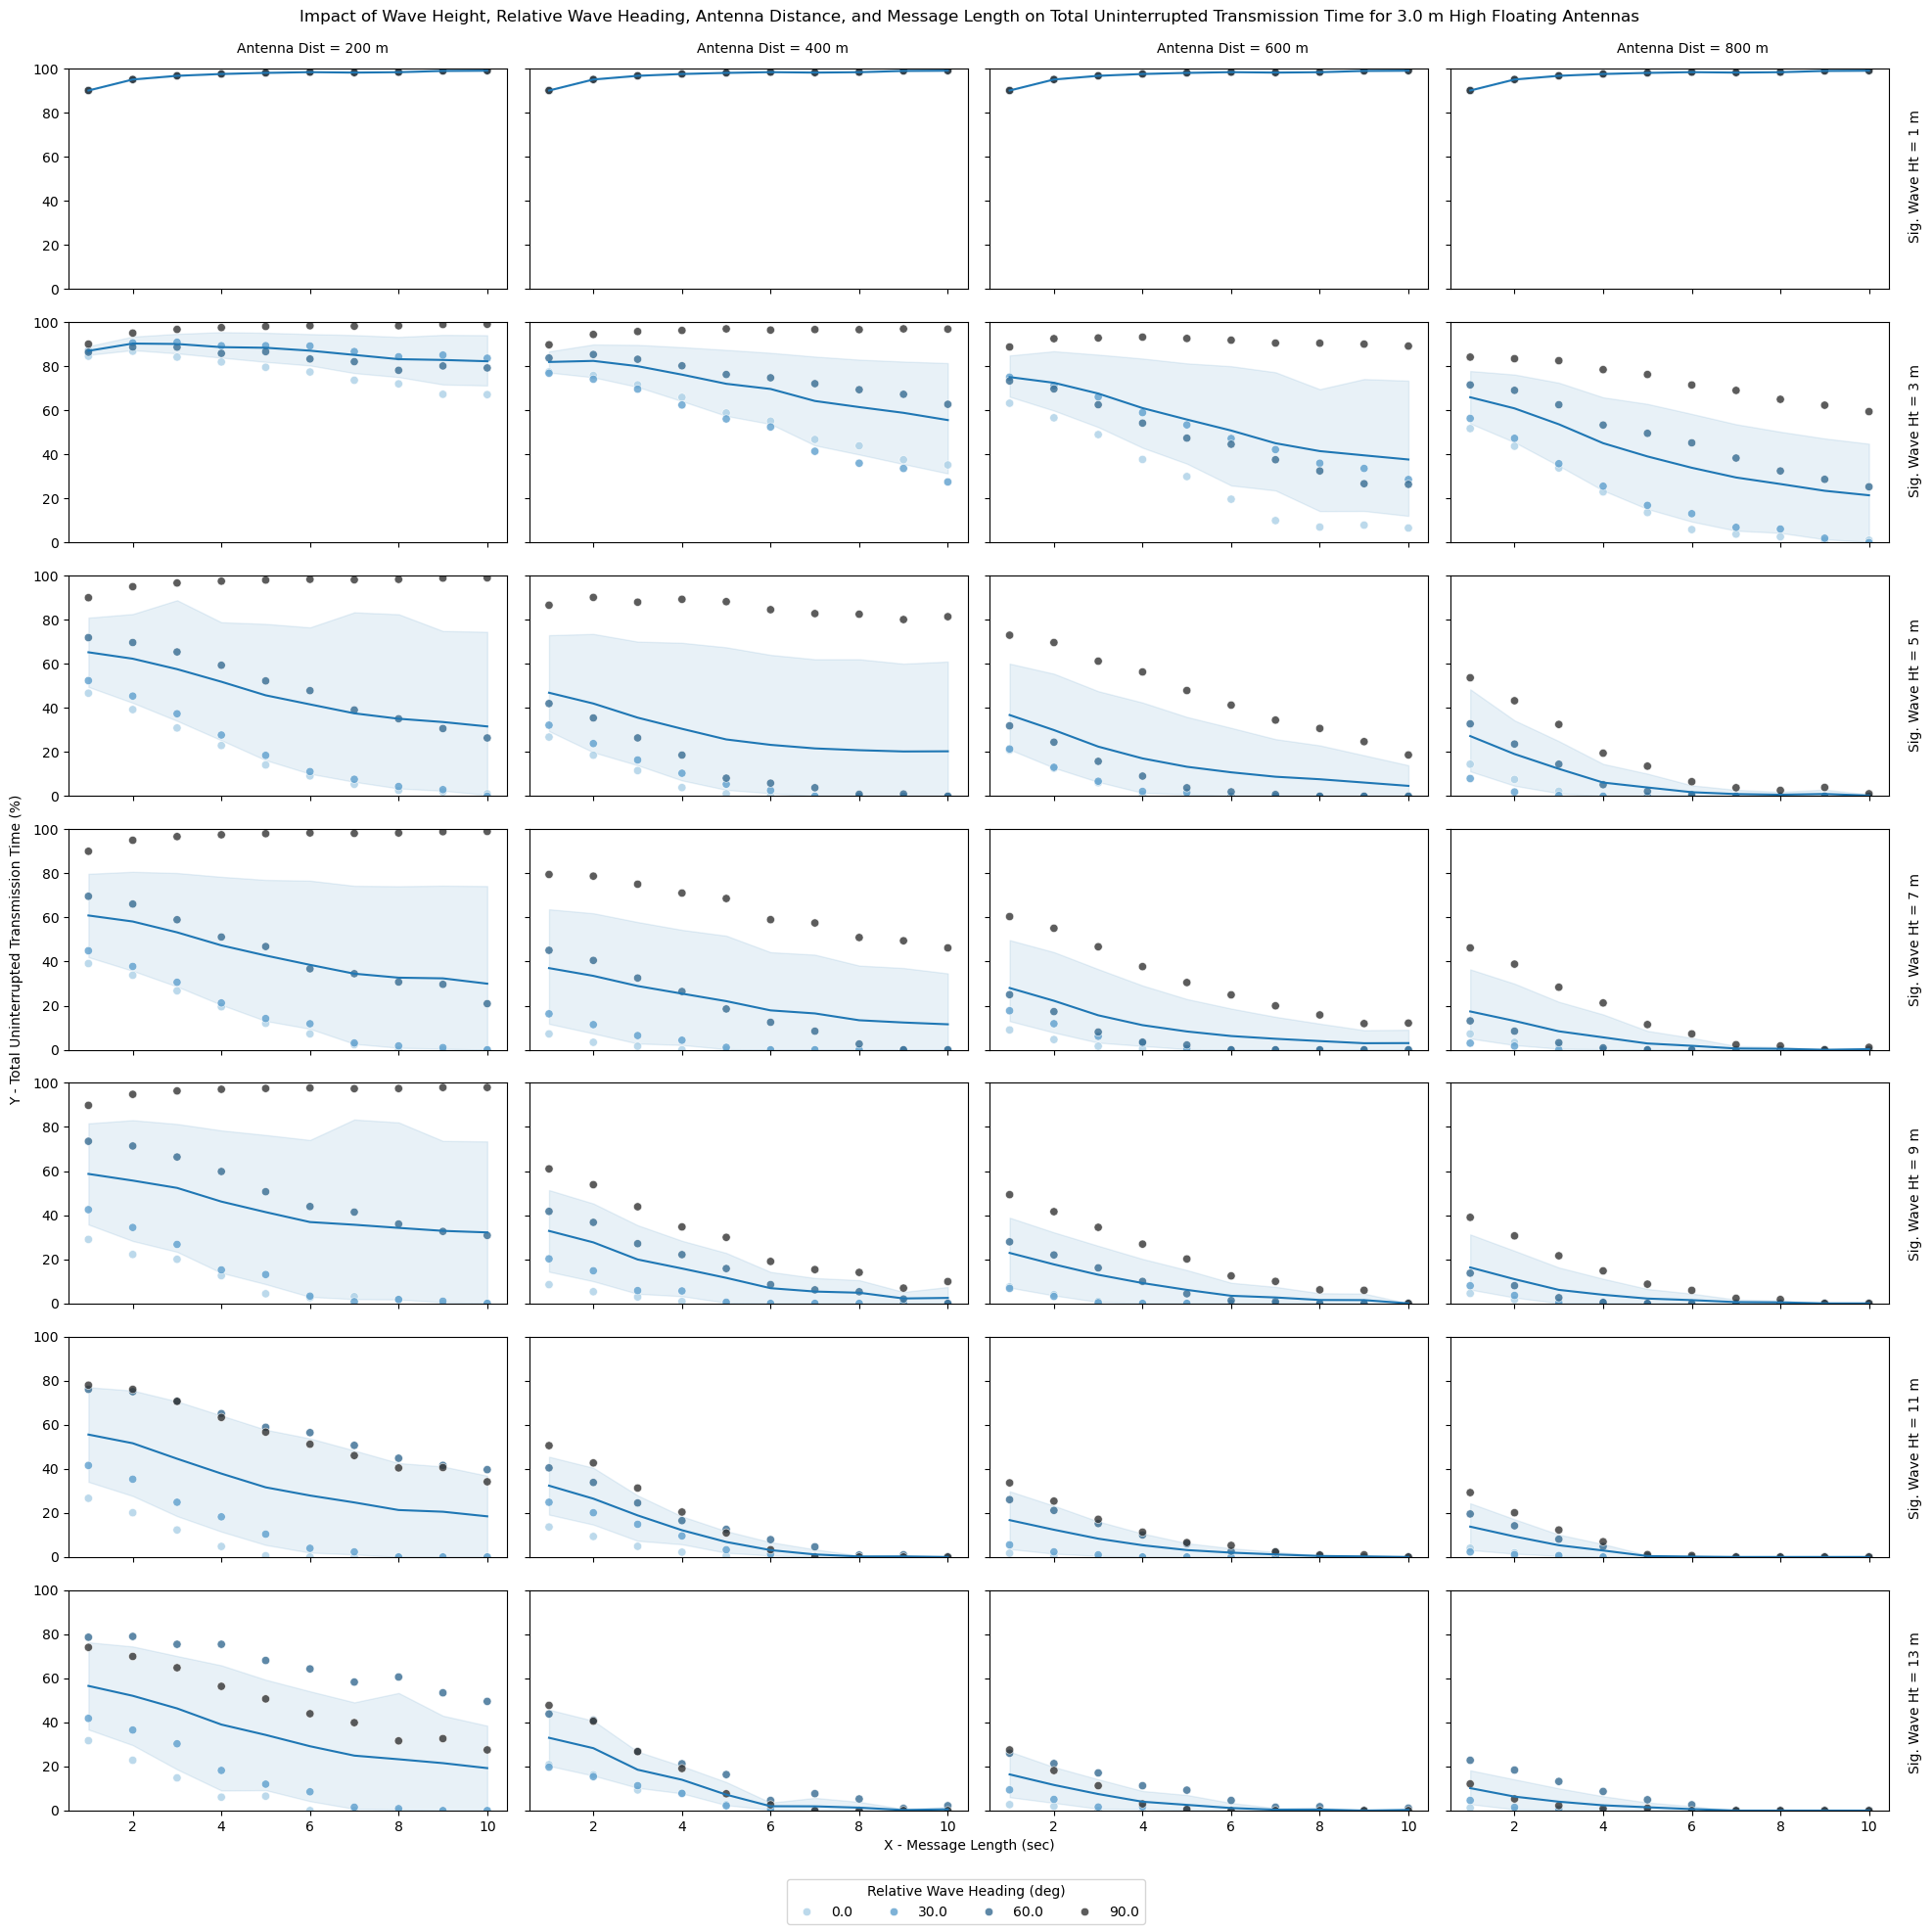

In [8]:
# Set figure size
width = 20
height = 20
plt.rcParams['figure.figsize'] = [width, height]

# Plot
plt.clf()
num_rows = len(wave_hss)
num_cols = len(ant_dists)
fig, axes = plt.subplots(num_rows, num_cols, sharex=True, sharey=True)
plt.subplots_adjust(left=0.04, right=0.97, top=0.95, bottom=0.06, hspace=0.15, wspace=0.05,)
# Defining custom 'ylim' values.
custom_ylim = (0, 100)
# Setting the values for all axes.
handles = None 
labels = None
plt.setp(axes, ylim=custom_ylim)
for i in range(num_rows):
    for j in range(num_cols):
        wave_hs = wave_hss[i]
        ant_dist = ant_dists[j]
        data = df_filtered.loc[(df_filtered["hs(m)"] == wave_hs) & (df_filtered["dist(m)"] == ant_dist)]
        lineplt = sns.lineplot(data=data, x="message_length(sec)", y="uninterrupted_time(%)", estimator="mean", errorbar="ci", err_kws={"alpha":0.1}, ax=axes[i][j])
        lineplt.set(xlabel=None, ylabel=None)
        scatterplt = sns.scatterplot(data=data, x="message_length(sec)", y="uninterrupted_time(%)", hue="relative_wave_heading(deg)", legend="full", palette="Blues_d", alpha=0.8, ax=axes[i][j])
        scatterplt.set(xlabel=None, ylabel=None)
        handles, labels = axes[i][j].get_legend_handles_labels()
        axes[i][j].get_legend().remove()
# fig.legend(title="Significant wave height (m)", handles=handles, labels=labels, loc="lower center", ncols=13) 
fig.legend(title="Relative Wave Heading (deg)", handles=handles, labels=labels, loc="lower center", ncols=13) 
fig.suptitle("Impact of Wave Height, Relative Wave Heading, Antenna Distance, and Message Length on Total Uninterrupted Transmission Time for {} m High Floating Antennas".format(selected_ant_ht))
# Add text
fig.text(0.5, 0.04, 'X - Message Length (sec)', ha='center')
fig.text(0.01, 0.5, 'Y - Total Uninterrupted Transmission Time (%)', va='center', rotation='vertical')
x = 0.165
y = 0.958
dx = 0.235
for i in range(len(ant_dists)):
    fig.text(x+(i*dx), y, 'Antenna Dist = {} m'.format(ant_dists[i]), ha='center')
x = 0.98
y = 0.895
dy = 0.13
for i in range(len(wave_hss)):
    fig.text(x, y-(i*dy), 'Sig. Wave Ht = {} m'.format(wave_hss[i]), va='center', rotation='vertical')
# fig.tight_layout()
file_fig = dir_fig.joinpath("plot_percent_time.png")
plt.savefig(file_fig, dpi=200)
plt.show()

<Figure size 2000x2000 with 0 Axes>

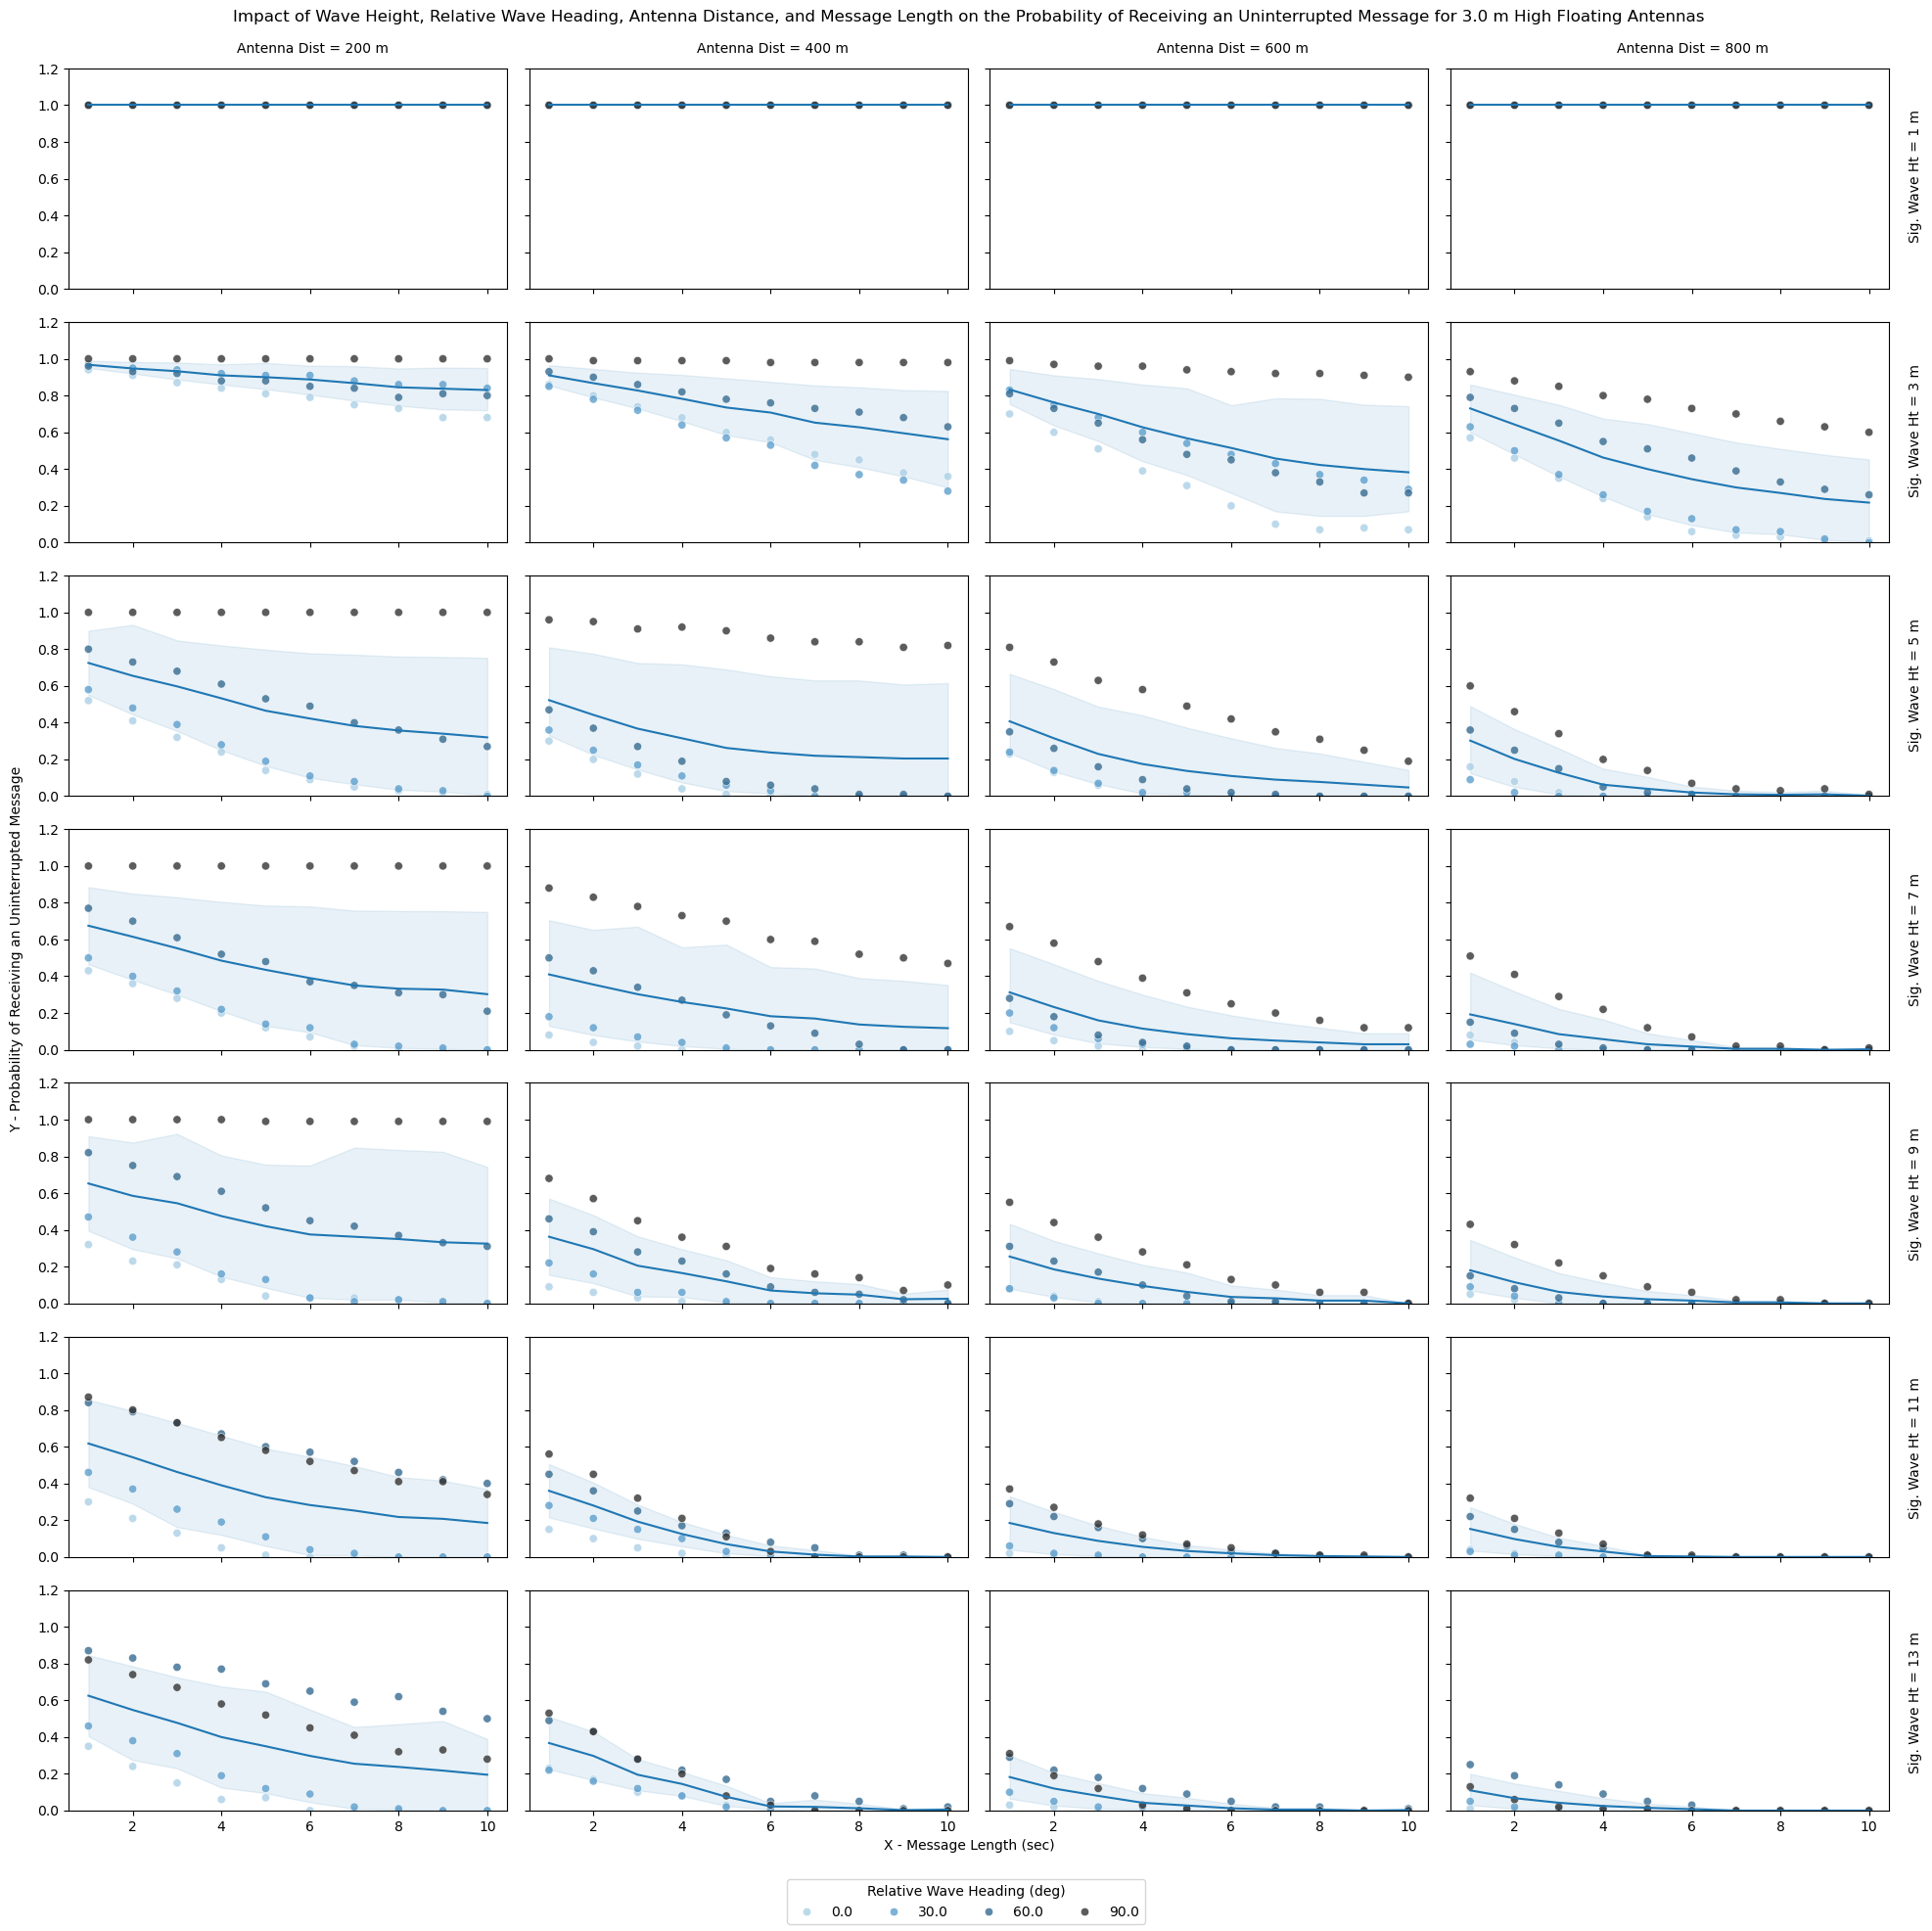

In [12]:
# Set figure size
width = 20
height = 20
plt.rcParams['figure.figsize'] = [width, height]

# Plot
plt.clf()
num_rows = len(wave_hss)
num_cols = len(ant_dists)
fig, axes = plt.subplots(num_rows, num_cols, sharex=True, sharey=True)
plt.subplots_adjust(left=0.04, right=0.97, top=0.95, bottom=0.06, hspace=0.15, wspace=0.05,)
# Defining custom 'ylim' values.
custom_ylim = (0, 1.2)
# Setting the values for all axes.
handles = None 
labels = None
plt.setp(axes, ylim=custom_ylim)
for i in range(num_rows):
    for j in range(num_cols):
        wave_hs = wave_hss[i]
        ant_dist = ant_dists[j]
        data = df_filtered.loc[(df_filtered["hs(m)"] == wave_hs) & (df_filtered["dist(m)"] == ant_dist)]
        lineplt = sns.lineplot(data=data, x="message_length(sec)", y="uninterrupted_message_probability", estimator="mean", errorbar="ci", err_kws={"alpha":0.1}, ax=axes[i][j])
        lineplt.set(xlabel=None, ylabel=None)
        scatterplt = sns.scatterplot(data=data, x="message_length(sec)", y="uninterrupted_message_probability", hue="relative_wave_heading(deg)", legend="full", palette="Blues_d", alpha=0.8, ax=axes[i][j])
        scatterplt.set(xlabel=None, ylabel=None)
        handles, labels = axes[i][j].get_legend_handles_labels()
        axes[i][j].get_legend().remove()
# fig.legend(title="Significant wave height (m)", handles=handles, labels=labels, loc="lower center", ncols=13) 
fig.legend(title="Relative Wave Heading (deg)", handles=handles, labels=labels, loc="lower center", ncols=13) 
fig.suptitle("Impact of Wave Height, Relative Wave Heading, Antenna Distance, and Message Length on the Probability of Receiving an Uninterrupted Message for {} m High Floating Antennas".format(selected_ant_ht))
# Add text
fig.text(0.5, 0.04, 'X - Message Length (sec)', ha='center')
fig.text(0.01, 0.5, 'Y - Probability of Receiving an Uninterrupted Message', va='center', rotation='vertical')
x = 0.165
y = 0.958
dx = 0.235
for i in range(len(ant_dists)):
    fig.text(x+(i*dx), y, 'Antenna Dist = {} m'.format(ant_dists[i]), ha='center')
x = 0.98
y = 0.895
dy = 0.13
for i in range(len(wave_hss)):
    fig.text(x, y-(i*dy), 'Sig. Wave Ht = {} m'.format(wave_hss[i]), va='center', rotation='vertical')
# fig.tight_layout()
file_fig = dir_fig.joinpath("plot_probability.png")
plt.savefig(file_fig, dpi=200)
plt.show()